<a href="https://colab.research.google.com/github/Luwii22/HTML/blob/main/CYB_302_Biometrics_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
print("CYB 302 - Biometrics Security Laboratory")
print("Python environment is ready!")

CYB 302 - Biometrics Security Laboratory
Python environment is ready!


In [2]:
!pip install opencv-python-headless numpy matplotlib scikit-learn seaborn

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import seaborn as sns

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("All libraries loaded successfully!")

OpenCV: 5.0.0
NumPy: 2.4.6
Scikit-learn: 1.6.1
All libraries loaded successfully!


In [4]:
import os
import urllib.request
import zipfile

dataset_url = "https://www.cl.cam.ac.uk/research/dtg/attarchive/pub/data/att_faces.zip"

zip_path = "/content/att_faces.zip"
dataset_path = "/content/att_faces"

print("Downloading ORL Face Database...")

urllib.request.urlretrieve(dataset_url, zip_path)

print("Download completed!")

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(dataset_path)

print("Dataset extracted successfully!")

Download completed!
Dataset extracted successfully!


In [5]:
import os

subjects = sorted([
    folder for folder in os.listdir(dataset_path)
    if folder.startswith("s") and os.path.isdir(os.path.join(dataset_path, folder))
])

print("Number of subjects:", len(subjects))

for subject in subjects[:5]:
    folder_path = os.path.join(dataset_path, subject)
    images = [f for f in os.listdir(folder_path) if f.endswith(".pgm")]
    print(subject, ":", len(images), "images")

Number of subjects: 40
s1 : 10 images
s10 : 10 images
s11 : 10 images
s12 : 10 images
s13 : 10 images


In [6]:
total_images = 0

for subject in subjects:
    folder_path = os.path.join(dataset_path, subject)
    images = [f for f in os.listdir(folder_path)
              if f.lower().endswith(".pgm")]

    total_images += len(images)

print("Total subjects:", len(subjects))
print("Total biometric images:", total_images)
print("Average images per subject:", total_images / len(subjects))

Total subjects: 40
Total biometric images: 400
Average images per subject: 10.0


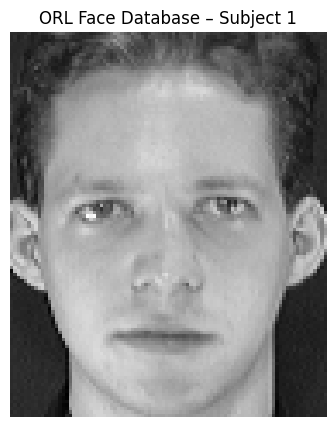

Image dimensions: (112, 92)


In [7]:
import cv2
import matplotlib.pyplot as plt

sample_path = os.path.join(dataset_path, "s1", "1.pgm")

image = cv2.imread(sample_path, cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(5, 5))
plt.imshow(image, cmap="gray")
plt.title("ORL Face Database – Subject 1")
plt.axis("off")
plt.show()

print("Image dimensions:", image.shape)

In [8]:
import os

enrollment_data = {}
testing_data = {}

for subject in subjects:
    folder_path = os.path.join(dataset_path, subject)

    images = sorted(
        [f for f in os.listdir(folder_path)
         if f.lower().endswith(".pgm")],
        key=lambda x: int(os.path.splitext(x)[0])
    )

    enrollment_data[subject] = images[:6]
    testing_data[subject] = images[6:]

print("ENROLMENT AND TESTING SPLIT")
print("--------------------------------")
print("Subjects:", len(subjects))
print("Enrolment images:",
      sum(len(v) for v in enrollment_data.values()))
print("Testing images:",
      sum(len(v) for v in testing_data.values()))
print("Total images:",
      sum(len(v) for v in enrollment_data.values()) +
      sum(len(v) for v in testing_data.values()))

ENROLMENT AND TESTING SPLIT
--------------------------------
Subjects: 40
Enrolment images: 240
Testing images: 160
Total images: 400


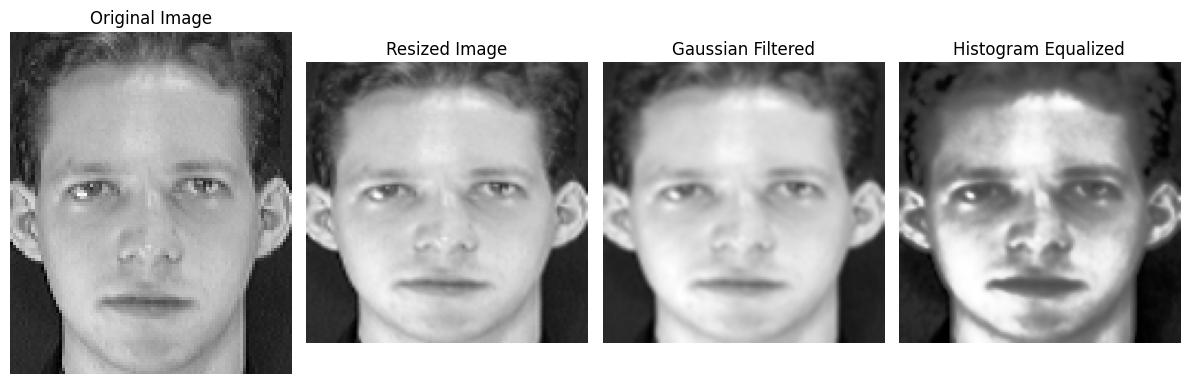

Original dimensions: (112, 92)
Resized dimensions: (128, 128)
Normalized pixel range: 0.058823529411764705 to 0.8235294117647058
Preprocessing completed successfully!


In [9]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# Load a sample face image in grayscale
sample_path = os.path.join(dataset_path, "s1", "1.pgm")
original = cv2.imread(sample_path, cv2.IMREAD_GRAYSCALE)

# Resize the image to a standard size
resized = cv2.resize(original, (128, 128))

# Normalize pixel values to the range 0–1
normalized = resized / 255.0

# Apply Gaussian filtering to reduce noise
blurred = cv2.GaussianBlur(resized, (3, 3), 0)

# Apply histogram equalization to improve contrast
enhanced = cv2.equalizeHist(blurred)

# Display preprocessing stages
images = [original, resized, blurred, enhanced]
titles = [
    "Original Image",
    "Resized Image",
    "Gaussian Filtered",
    "Histogram Equalized"
]

plt.figure(figsize=(12, 5))

for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(images[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Original dimensions:", original.shape)
print("Resized dimensions:", resized.shape)
print("Normalized pixel range:",
      normalized.min(), "to", normalized.max())
print("Preprocessing completed successfully!")


ORIGINAL IMAGE
Minimum pixel value: 11
Maximum pixel value: 234
Mean pixel intensity: 128.34

ENHANCED IMAGE
Minimum pixel value: 0
Maximum pixel value: 255
Mean pixel intensity: 128.73


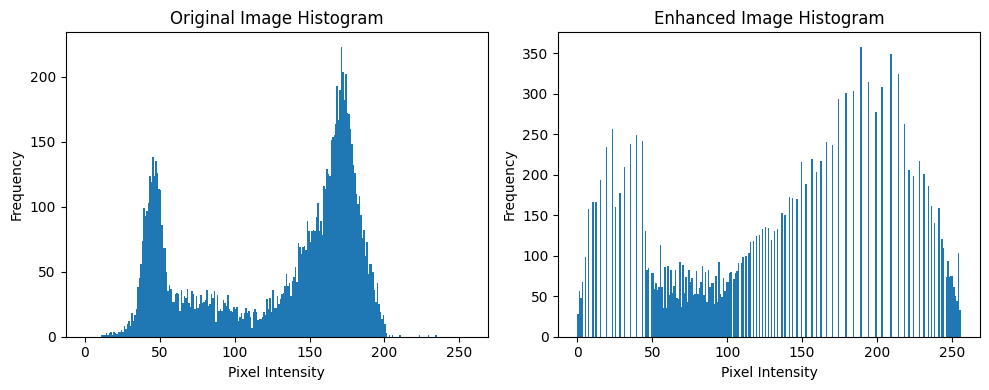

In [10]:

# Compare pixel intensity statistics before and after enhancement

print("ORIGINAL IMAGE")
print("Minimum pixel value:", original.min())
print("Maximum pixel value:", original.max())
print("Mean pixel intensity:", round(original.mean(), 2))

print("\nENHANCED IMAGE")
print("Minimum pixel value:", enhanced.min())
print("Maximum pixel value:", enhanced.max())
print("Mean pixel intensity:", round(enhanced.mean(), 2))

# Display intensity histograms
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(original.ravel(), bins=256, range=(0, 256))
plt.title("Original Image Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.subplot(1, 2, 2)
plt.hist(enhanced.ravel(), bins=256, range=(0, 256))
plt.title("Enhanced Image Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


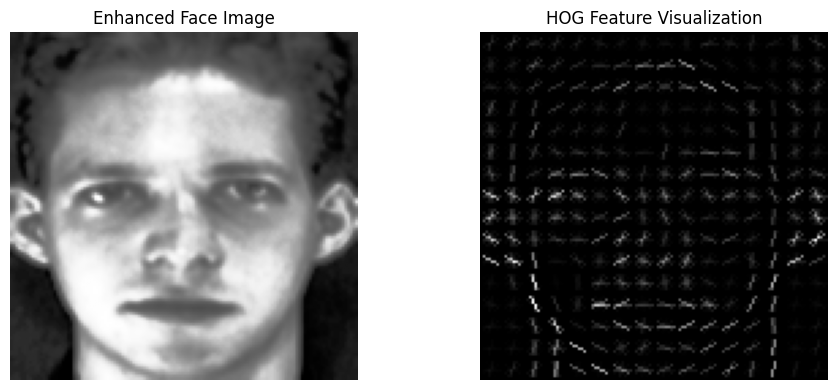

Feature extraction completed!
Feature vector length: 8100
Feature vector sample: [0.27415427 0.18868717 0.27415427 0.0718856  0.09616852 0.
 0.02212979 0.02821005 0.         0.27415427 0.27415427 0.17142247
 0.27415427 0.07694013 0.04036892]


In [11]:

from skimage.feature import hog

# Extract HOG features from the enhanced sample image
features, hog_image = hog(
    enhanced,
    orientations=9,
    pixels_per_cell=(8, 8),
    cells_per_block=(2, 2),
    visualize=True,
    feature_vector=True
)

# Display original enhanced image and HOG visualization
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(enhanced, cmap="gray")
plt.title("Enhanced Face Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hog_image, cmap="gray")
plt.title("HOG Feature Visualization")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Feature extraction completed!")
print("Feature vector length:", len(features))
print("Feature vector sample:", features[:15])


In [12]:

from skimage.feature import hog
import numpy as np
import os
import cv2

# Store biometric templates and their subject labels
templates = []
labels = []

for subject in subjects:
    folder_path = os.path.join(dataset_path, subject)

    for image_file in enrollment_data[subject]:
        image_path = os.path.join(folder_path, image_file)

        # Load and preprocess image
        img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (128, 128))
        img = cv2.GaussianBlur(img, (3, 3), 0)
        img = cv2.equalizeHist(img)

        # Extract HOG features
        feature_vector = hog(
            img,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            feature_vector=True
        )

        templates.append(feature_vector)
        labels.append(subject)

# Convert templates into a NumPy array
templates = np.array(templates)
labels = np.array(labels)

print("BIOMETRIC TEMPLATE CREATION")
print("---------------------------")
print("Number of templates:", len(templates))
print("Number of subjects:", len(set(labels)))
print("Template dimensions:", templates.shape)
print("First template sample:", templates[0][:10])
print("Template creation completed successfully!")


BIOMETRIC TEMPLATE CREATION
---------------------------
Number of templates: 240
Number of subjects: 40
Template dimensions: (240, 8100)
First template sample: [0.27415427 0.18868717 0.27415427 0.0718856  0.09616852 0.
 0.02212979 0.02821005 0.         0.27415427]
Template creation completed successfully!


In [13]:

test_features = []
test_labels = []

for subject in subjects:
    folder_path = os.path.join(dataset_path, subject)

    for image_file in testing_data[subject]:
        image_path = os.path.join(folder_path, image_file)

        # Load and preprocess testing image
        img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (128, 128))
        img = cv2.GaussianBlur(img, (3, 3), 0)
        img = cv2.equalizeHist(img)

        # Extract HOG features
        feature_vector = hog(
            img,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            feature_vector=True
        )

        test_features.append(feature_vector)
        test_labels.append(subject)

# Convert to NumPy arrays
test_features = np.array(test_features)
test_labels = np.array(test_labels)

print("TESTING FEATURE EXTRACTION")
print("---------------------------")
print("Testing images processed:", len(test_features))
print("Testing subjects:", len(set(test_labels)))
print("Testing feature dimensions:", test_features.shape)
print("Feature extraction completed successfully!")


TESTING FEATURE EXTRACTION
---------------------------
Testing images processed: 160
Testing subjects: 40
Testing feature dimensions: (160, 8100)
Feature extraction completed successfully!


In [14]:

from sklearn.metrics.pairwise import euclidean_distances

# Compare every testing image with every enrolment template
distance_matrix = euclidean_distances(
    test_features,
    templates
)

print("BIOMETRIC MATCHING RESULTS")
print("--------------------------")
print("Distance matrix shape:", distance_matrix.shape)

# Find the closest enrolment template for each testing image
predicted_indices = np.argmin(distance_matrix, axis=1)

predicted_labels = labels[predicted_indices]

# Calculate identification accuracy
correct_matches = np.sum(predicted_labels == test_labels)
accuracy = (correct_matches / len(test_labels)) * 100

print("Correct identifications:", correct_matches)
print("Incorrect identifications:", len(test_labels) - correct_matches)
print("Identification accuracy:", round(accuracy, 2), "%")

print("\nFirst 10 matching comparisons:")
for i in range(10):
    print(
        "Actual:", test_labels[i],
        "| Predicted:", predicted_labels[i],
        "| Distance:", round(distance_matrix[i, predicted_indices[i]], 2)
    )


BIOMETRIC MATCHING RESULTS
--------------------------
Distance matrix shape: (160, 240)
Correct identifications: 142
Incorrect identifications: 18
Identification accuracy: 88.75 %

First 10 matching comparisons:
Actual: s1 | Predicted: s11 | Distance: 11.38
Actual: s1 | Predicted: s1 | Distance: 11.5
Actual: s1 | Predicted: s11 | Distance: 12.43
Actual: s1 | Predicted: s13 | Distance: 11.63
Actual: s10 | Predicted: s10 | Distance: 10.08
Actual: s10 | Predicted: s10 | Distance: 8.08
Actual: s10 | Predicted: s23 | Distance: 12.4
Actual: s10 | Predicted: s4 | Distance: 10.95
Actual: s11 | Predicted: s11 | Distance: 10.01
Actual: s11 | Predicted: s15 | Distance: 11.5


GENUINE AND IMPOSTOR SCORE ANALYSIS
-----------------------------------
Genuine comparisons: 960
Impostor comparisons: 37440

Genuine distance statistics:
Minimum: 5.85
Maximum: 15.06
Mean: 11.38

Impostor distance statistics:
Minimum: 10.51
Maximum: 15.92
Mean: 13.32


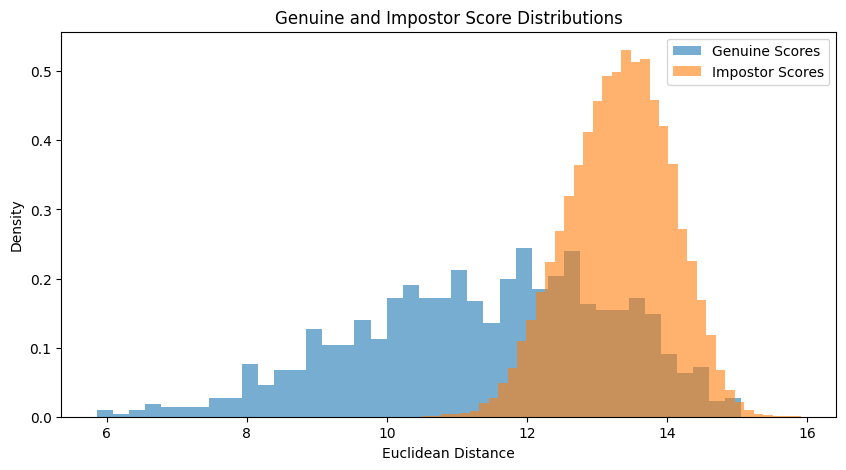

In [15]:

# Separate genuine and impostor distance scores

same_person = test_labels[:, None] == labels[None, :]

genuine_scores = distance_matrix[same_person]
impostor_scores = distance_matrix[~same_person]

print("GENUINE AND IMPOSTOR SCORE ANALYSIS")
print("-----------------------------------")
print("Genuine comparisons:", len(genuine_scores))
print("Impostor comparisons:", len(impostor_scores))

print("\nGenuine distance statistics:")
print("Minimum:", round(genuine_scores.min(), 2))
print("Maximum:", round(genuine_scores.max(), 2))
print("Mean:", round(genuine_scores.mean(), 2))

print("\nImpostor distance statistics:")
print("Minimum:", round(impostor_scores.min(), 2))
print("Maximum:", round(impostor_scores.max(), 2))
print("Mean:", round(impostor_scores.mean(), 2))

# Plot score distributions
plt.figure(figsize=(10, 5))

plt.hist(genuine_scores, bins=40, alpha=0.6,
         label="Genuine Scores", density=True)

plt.hist(impostor_scores, bins=40, alpha=0.6,
         label="Impostor Scores", density=True)

plt.title("Genuine and Impostor Score Distributions")
plt.xlabel("Euclidean Distance")
plt.ylabel("Density")
plt.legend()
plt.show()


In [16]:

# Calculate a starting threshold using genuine and impostor scores
threshold = (genuine_scores.mean() + impostor_scores.mean()) / 2

print("BIOMETRIC MATCHING THRESHOLD")
print("----------------------------")
print("Mean genuine distance:", round(genuine_scores.mean(), 2))
print("Mean impostor distance:", round(impostor_scores.mean(), 2))
print("Selected threshold:", round(threshold, 2))

# Test acceptance and rejection decisions
accepted_genuine = np.sum(genuine_scores <= threshold)
rejected_genuine = np.sum(genuine_scores > threshold)

accepted_impostor = np.sum(impostor_scores <= threshold)
rejected_impostor = np.sum(impostor_scores > threshold)

print("\nMATCHING DECISIONS")
print("------------------")
print("Genuine attempts accepted:", accepted_genuine)
print("Genuine attempts rejected:", rejected_genuine)
print("Impostor attempts accepted:", accepted_impostor)
print("Impostor attempts rejected:", rejected_impostor)


BIOMETRIC MATCHING THRESHOLD
----------------------------
Mean genuine distance: 11.38
Mean impostor distance: 13.32
Selected threshold: 12.35

MATCHING DECISIONS
------------------
Genuine attempts accepted: 634
Genuine attempts rejected: 326
Impostor attempts accepted: 3808
Impostor attempts rejected: 33632


In [17]:

# Test several threshold values
thresholds = [
    genuine_scores.mean(),
    (genuine_scores.mean() + impostor_scores.mean()) / 2,
    impostor_scores.mean()
]

print("THRESHOLD COMPARISON")
print("--------------------")

for value in thresholds:
    genuine_accepted = np.sum(genuine_scores <= value)
    impostor_accepted = np.sum(impostor_scores <= value)

    genuine_rejected = len(genuine_scores) - genuine_accepted
    impostor_rejected = len(impostor_scores) - impostor_accepted

    print("\nThreshold:", round(value, 2))
    print("Genuine accepted:", genuine_accepted)
    print("Genuine rejected:", genuine_rejected)
    print("Impostor accepted:", impostor_accepted)
    print("Impostor rejected:", impostor_rejected)


THRESHOLD COMPARISON
--------------------

Threshold: 11.38
Genuine accepted: 457
Genuine rejected: 503
Impostor accepted: 159
Impostor rejected: 37281

Threshold: 12.35
Genuine accepted: 634
Genuine rejected: 326
Impostor accepted: 3808
Impostor rejected: 33632

Threshold: 13.32
Genuine accepted: 809
Genuine rejected: 151
Impostor accepted: 18048
Impostor rejected: 19392


In [18]:

# Calculate False Acceptance Rate (FAR)
false_accepts = np.sum(impostor_scores <= threshold)

FAR = (false_accepts / len(impostor_scores)) * 100

# Calculate False Rejection Rate (FRR)
false_rejections = np.sum(genuine_scores > threshold)

FRR = (false_rejections / len(genuine_scores)) * 100

print("BIOMETRIC ERROR RATE ANALYSIS")
print("-----------------------------")
print("Total genuine comparisons:", len(genuine_scores))
print("Total impostor comparisons:", len(impostor_scores))

print("\nFalse accepts:", false_accepts)
print("False rejections:", false_rejections)

print("\nFalse Acceptance Rate (FAR):", round(FAR, 2), "%")
print("False Rejection Rate (FRR):", round(FRR, 2), "%")


BIOMETRIC ERROR RATE ANALYSIS
-----------------------------
Total genuine comparisons: 960
Total impostor comparisons: 37440

False accepts: 3808
False rejections: 326

False Acceptance Rate (FAR): 10.17 %
False Rejection Rate (FRR): 33.96 %


ROC AND EER ANALYSIS
--------------------
Equal Error Rate (EER): 24.17 %
ROC AUC: 0.8315
Approximate EER distance threshold: 12.8


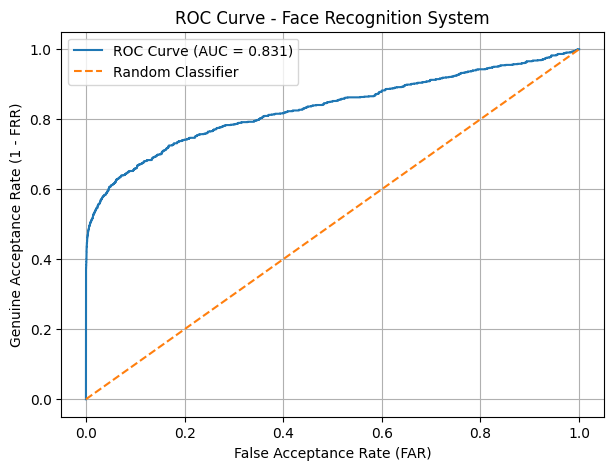

In [19]:

from sklearn.metrics import roc_curve, auc

# Combine genuine and impostor scores
y_true = np.concatenate([
    np.ones(len(genuine_scores)),
    np.zeros(len(impostor_scores))
])

# Lower Euclidean distance means a better match.
# Negate distances because roc_curve expects higher scores to mean positive.
all_scores = np.concatenate([
    genuine_scores,
    impostor_scores
])

y_scores = -all_scores

# Generate ROC data
fpr, tpr, roc_thresholds = roc_curve(y_true, y_scores)

# Calculate FRR and EER
fnr = 1 - tpr
eer_index = np.argmin(np.abs(fpr - fnr))

EER = (fpr[eer_index] + fnr[eer_index]) / 2 * 100
roc_auc = auc(fpr, tpr)

print("ROC AND EER ANALYSIS")
print("--------------------")
print("Equal Error Rate (EER):", round(EER, 2), "%")
print("ROC AUC:", round(roc_auc, 4))
print("Approximate EER distance threshold:",
      round(-roc_thresholds[eer_index], 2))

# Plot ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Acceptance Rate (FAR)")
plt.ylabel("Genuine Acceptance Rate (1 - FRR)")
plt.title("ROC Curve - Face Recognition System")
plt.legend()
plt.grid()
plt.show()


In [21]:

from skimage.feature import local_binary_pattern

radius = 2
n_points = 8 * radius

def extract_lbp_histogram(image):
    lbp = local_binary_pattern(
        image, n_points, radius, method="uniform"
    )

    hist, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(0, n_points + 3),
        range=(0, n_points + 2),
        density=True
    )

    return hist

# Regenerate enrolment LBP features
lbp_templates = []

for subject in subjects:
    folder_path = os.path.join(dataset_path, subject)

    for image_file in enrollment_data[subject]:
        image_path = os.path.join(folder_path, image_file)

        img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (128, 128))
        img = cv2.GaussianBlur(img, (3, 3), 0)
        img = cv2.equalizeHist(img)

        lbp_templates.append(extract_lbp_histogram(img))

# Regenerate testing LBP features
lbp_test_features = []

for subject in subjects:
    folder_path = os.path.join(dataset_path, subject)

    for image_file in testing_data[subject]:
        image_path = os.path.join(folder_path, image_file)

        img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
        img = cv2.resize(img, (128, 128))
        img = cv2.GaussianBlur(img, (3, 3), 0)
        img = cv2.equalizeHist(img)

        lbp_test_features.append(extract_lbp_histogram(img))

lbp_templates = np.array(lbp_templates)
lbp_test_features = np.array(lbp_test_features)

print("CORRECTED LBP FEATURE EXTRACTION")
print("--------------------------------")
print("Enrolment templates:", lbp_templates.shape)
print("Testing features:", lbp_test_features.shape)
print("Feature dimensions consistent:",
      lbp_templates.shape[1] == lbp_test_features.shape[1])


CORRECTED LBP FEATURE EXTRACTION
--------------------------------
Enrolment templates: (240, 18)
Testing features: (160, 18)
Feature dimensions consistent: True


In [22]:

from sklearn.metrics.pairwise import euclidean_distances

# Calculate LBP distance matrix
lbp_distance_matrix = euclidean_distances(
    lbp_test_features,
    lbp_templates
)

# Normalize HOG and LBP distances separately
hog_min = distance_matrix.min()
hog_max = distance_matrix.max()

lbp_min = lbp_distance_matrix.min()
lbp_max = lbp_distance_matrix.max()

hog_normalized = (
    (distance_matrix - hog_min) / (hog_max - hog_min)
)

lbp_normalized = (
    (lbp_distance_matrix - lbp_min) / (lbp_max - lbp_min)
)

# Combine normalized scores using equal weighting
fusion_scores = (
    0.5 * hog_normalized +
    0.5 * lbp_normalized
)

# Identify the closest matching subject
fusion_predictions = labels[np.argmin(fusion_scores, axis=1)]

fusion_correct = np.sum(fusion_predictions == test_labels)
fusion_accuracy = fusion_correct / len(test_labels) * 100

print("HOG AND LBP SCORE FUSION")
print("------------------------")
print("HOG distance matrix:", distance_matrix.shape)
print("LBP distance matrix:", lbp_distance_matrix.shape)
print("Fusion matrix:", fusion_scores.shape)
print("Correct identifications:", fusion_correct)
print("Incorrect identifications:",
      len(test_labels) - fusion_correct)
print("Fusion identification accuracy:",
      round(fusion_accuracy, 2), "%")


HOG AND LBP SCORE FUSION
------------------------
HOG distance matrix: (160, 240)
LBP distance matrix: (160, 240)
Fusion matrix: (160, 240)
Correct identifications: 142
Incorrect identifications: 18
Fusion identification accuracy: 88.75 %


HOG + LBP FUSION PERFORMANCE
-----------------------------
Genuine comparisons: 960
Impostor comparisons: 37440
Fusion threshold: 0.4104
Fusion FAR: 16.07 %
Fusion FRR: 23.65 %
Fusion identification accuracy: 88.75 %


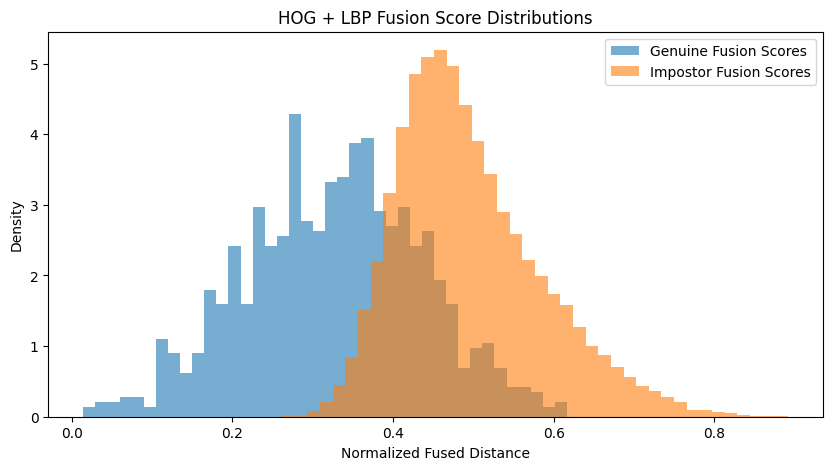

In [23]:

# Separate genuine and impostor fusion scores
same_person = test_labels[:, None] == labels[None, :]

fusion_genuine = fusion_scores[same_person]
fusion_impostor = fusion_scores[~same_person]

# Calculate an initial fusion threshold
fusion_threshold = (
    fusion_genuine.mean() + fusion_impostor.mean()
) / 2

# Calculate FAR and FRR
fusion_false_accepts = np.sum(
    fusion_impostor <= fusion_threshold
)

fusion_false_rejections = np.sum(
    fusion_genuine > fusion_threshold
)

fusion_far = (
    fusion_false_accepts / len(fusion_impostor)
) * 100

fusion_frr = (
    fusion_false_rejections / len(fusion_genuine)
) * 100

print("HOG + LBP FUSION PERFORMANCE")
print("-----------------------------")
print("Genuine comparisons:", len(fusion_genuine))
print("Impostor comparisons:", len(fusion_impostor))
print("Fusion threshold:", round(fusion_threshold, 4))
print("Fusion FAR:", round(fusion_far, 2), "%")
print("Fusion FRR:", round(fusion_frr, 2), "%")
print("Fusion identification accuracy:",
      round(fusion_accuracy, 2), "%")

# Plot fusion score distributions
plt.figure(figsize=(10, 5))

plt.hist(fusion_genuine, bins=40, alpha=0.6,
         density=True, label="Genuine Fusion Scores")

plt.hist(fusion_impostor, bins=40, alpha=0.6,
         density=True, label="Impostor Fusion Scores")

plt.title("HOG + LBP Fusion Score Distributions")
plt.xlabel("Normalized Fused Distance")
plt.ylabel("Density")
plt.legend()
plt.show()


In [24]:

!pip install cryptography


In [25]:

from cryptography.fernet import Fernet
import numpy as np

# Generate an encryption key
encryption_key = Fernet.generate_key()
cipher = Fernet(encryption_key)

# Select one biometric template
sample_template = templates[0]

# Convert template into bytes
template_bytes = sample_template.tobytes()

# Encrypt the biometric template
encrypted_template = cipher.encrypt(template_bytes)

# Decrypt the template
decrypted_bytes = cipher.decrypt(encrypted_template)

# Reconstruct the original numerical template
recovered_template = np.frombuffer(
    decrypted_bytes,
    dtype=sample_template.dtype
)

print("BIOMETRIC TEMPLATE ENCRYPTION")
print("-----------------------------")
print("Original template size:", len(template_bytes), "bytes")
print("Encrypted template size:", len(encrypted_template), "bytes")
print("Encryption successful:", encrypted_template != template_bytes)
print("Decryption successful:", np.array_equal(
    sample_template, recovered_template
))


BIOMETRIC TEMPLATE ENCRYPTION
-----------------------------
Original template size: 64800 bytes
Encrypted template size: 86500 bytes
Encryption successful: True
Decryption successful: True


In [26]:

# Simulate access control for biometric templates

authorized_users = ["admin", "biometric_operator"]

def access_template(username):
    if username in authorized_users:
        return "ACCESS GRANTED: Authorized user."
    else:
        return "ACCESS DENIED: Unauthorized access attempt."

# Test authorized access
print("Authorized access test:")
print(access_template("admin"))

# Test unauthorized access
print("\nUnauthorized access test:")
print(access_template("unknown_user"))

# Display access control policy
print("\nAUTHORIZED USERS")
for user in authorized_users:
    print("-", user)


Authorized access test:
ACCESS GRANTED: Authorized user.

Unauthorized access test:
ACCESS DENIED: Unauthorized access attempt.

AUTHORIZED USERS
- admin
- biometric_operator


FUSION EER ANALYSIS
-------------------
Fusion EER: 20.48 %
Approximate EER threshold: 0.4207


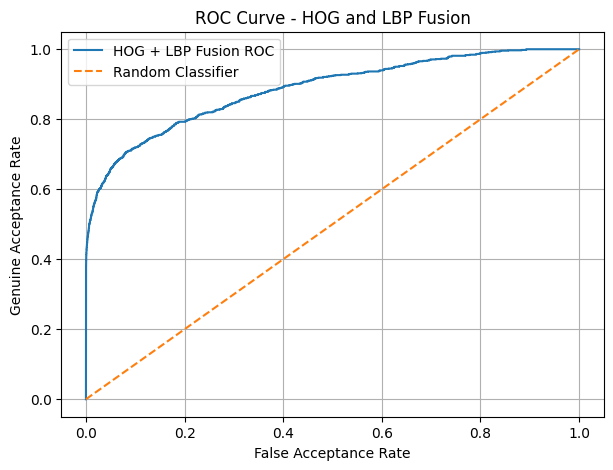

In [27]:

from sklearn.metrics import roc_curve
import numpy as np

# Genuine = 1, impostor = 0
fusion_y_true = np.concatenate([
    np.ones(len(fusion_genuine)),
    np.zeros(len(fusion_impostor))
])

# Lower distance means a better match
fusion_y_scores = -np.concatenate([
    fusion_genuine,
    fusion_impostor
])

fusion_fpr, fusion_tpr, fusion_roc_thresholds = roc_curve(
    fusion_y_true,
    fusion_y_scores
)

fusion_fnr = 1 - fusion_tpr

fusion_eer_index = np.argmin(
    np.abs(fusion_fpr - fusion_fnr)
)

fusion_eer = (
    fusion_fpr[fusion_eer_index] +
    fusion_fnr[fusion_eer_index]
) / 2 * 100

print("FUSION EER ANALYSIS")
print("-------------------")
print("Fusion EER:", round(fusion_eer, 2), "%")
print("Approximate EER threshold:",
      round(-fusion_roc_thresholds[fusion_eer_index], 4))

# Plot fusion ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fusion_fpr, fusion_tpr, label="HOG + LBP Fusion ROC")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Acceptance Rate")
plt.ylabel("Genuine Acceptance Rate")
plt.title("ROC Curve - HOG and LBP Fusion")
plt.legend()
plt.grid()
plt.show()
